In [1]:
!pip install pyamg

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 18.6 MB/s  0:00:00


In [2]:
import numpy as np
import scipy.sparse as sp
import pyamg
import matplotlib.pyplot as plt
import pandas as pd
import time
import inspect

print("Versión de PyAMG:", pyamg.__version__)

Versión de PyAMG: 5.4.1


EL objetivo es listar todos los suavisadores (smoothers) disponibles, como Jacobi, Gauss-Seidel y SOR, estos métodos son importantes porque eliminan el error de alta frcuencia y serán usados para ecelerar la convergencia.

In [3]:
import pyamg.relaxation as relaxation

print("Funciones disponibles en pyamg.relaxation:\n")

for nombre in dir(relaxation):
    if not nombre.startswith("_"):
        objeto = getattr(relaxation, nombre)

        if callable(objeto):
            print(nombre)

Funciones disponibles en pyamg.relaxation:



En esta celda se consultan las configuraciones predeterminadas de los métodos multigrid Ruge-Stüben y Smoothed Aggregation, implementados en la biblioteca PyAMG. Para ello, se utiliza la función inspect.signature(), que permite visualizar los argumentos de cada función, sus valores predeterminados y los parámetros opcionales.

El objetivo es identificar las diferencias entre ambos métodos en cuanto a sus parámetros de configuración, especialmente en los criterios de selección de fuerza, construcción de interpolación, suavizadores y número máximo de niveles de la jerarquía multigrid.
- Ruge-Stüben: utiliza por defecto el criterio de fuerza clásica con parámetro $\theta=0.25$, interpolación clásica y suavizadores Gauss-Seidel simétricos.
- Smoothed Aggregation: utiliza el criterio de fuerza simétrica, agregación estándar, suavización de Jacobi y suavizadores por bloques Gauss-Seidel simétricos.

Esta comparación permite conocer los parámetros que utiliza cada método antes de realizar experimentos numéricos y evaluar su comportamiento en la solución de sistemas lineales.

In [4]:
print("Configuración predeterminada de Ruge-Stüben:")
print(inspect.signature(pyamg.ruge_stuben_solver))

print("\nConfiguración predeterminada de Smoothed Aggregation:")
print(inspect.signature(pyamg.smoothed_aggregation_solver))

Configuración predeterminada de Ruge-Stüben:
(A, strength=('classical', {'theta': 0.25}), CF=('RS', {'second_pass': False}), interpolation='classical', presmoother=('gauss_seidel', {'sweep': 'symmetric'}), postsmoother=('gauss_seidel', {'sweep': 'symmetric'}), max_levels=30, max_coarse=10, keep=False, **kwargs)

Configuración predeterminada de Smoothed Aggregation:
(A, B=None, BH=None, symmetry='hermitian', strength='symmetric', aggregate='standard', smooth=('jacobi', {'omega': 1.3333333333333333}), presmoother=('block_gauss_seidel', {'sweep': 'symmetric'}), postsmoother=('block_gauss_seidel', {'sweep': 'symmetric'}), improve_candidates=(('block_gauss_seidel', {'sweep': 'symmetric', 'iterations': 4}), None), max_levels=10, max_coarse=10, diagonal_dominance=False, keep=False, **kwargs)


En esta celda se construye un sistema lineal $Ax=b$ a partir de la discretización de la ecuación de Poisson bidimensional, utilizando la función *pyamg.gallery.poisson()* de la biblioteca PyAMG.

Se establece una malla de tamaño $64\times64$, lo que genera una matriz de coeficientes $A$ de dimensiones $4096\times4096$. La matriz se almacena en formato disperso CSR (Compressed Sparse Row), con el propósito de optimizar el almacenamiento y las operaciones computacionales, ya que contiene una gran cantidad de elementos nulos.

Posteriormente, se definen:
- Vector del lado derecho $b$: se construye como un vector de unos.
- Aproximación inicial $x_0$: se establece como un vector de ceros, que servirá como punto de partida para los métodos iterativos.
Finalmente, se verifican las propiedades de la matriz obtenida:
- Sus dimensiones son $4096\times4096$.
- Contiene $20224$ elementos no nulos.
- Es simétrica, lo cual se comprueba mediante *np.allclose()*.

Estas características permiten establecer un problema de referencia para evaluar y comparar el desempeño de los métodos multigrid Ruge-Stüben y Smoothed Aggregation en la solución de sistemas lineales dispersos.

In [5]:
# Tamaño de la malla
n = 64

# Construcción de la matriz de Poisson 2D
A = pyamg.gallery.poisson(
    (n, n),
    format="csr"
)

# Vector del lado derecho
b = np.ones(A.shape[0])

# Aproximación inicial
x0 = np.zeros(A.shape[0])

print("Dimensiones de A:", A.shape)
print("Número de elementos no nulos:", A.nnz)
print("Es simétrica:", np.allclose(A.toarray(), A.toarray().T))

Dimensiones de A: (4096, 4096)
Número de elementos no nulos: 20224
Es simétrica: True


En esta celda se define un diccionario llamado configuraciones, que contiene cuatro alternativas de suavización para evaluar su influencia en el desempeño de los métodos multigrid.

Cada configuración establece los parámetros de los suavizadores previos (presmoother) y posteriores (postsmoother), los cuales se aplican durante las etapas de cada ciclo multigrid.

Se consideran las siguientes alternativas:
- Gauss-Seidel simétrico: utiliza el método Gauss-Seidel con barrido simétrico, tanto antes como después de la corrección.
- Jacobi: emplea el método de Jacobi con un parámetro de relajación \(\omega=0.7\).
- SOR: utiliza el método de relajación sucesiva con \(\omega=1.0\) y barrido simétrico.
- Sin suavizador: establece ambos parámetros como None, permitiendo analizar el comportamiento del método multigrid sin aplicar procesos de suavización.

El propósito de esta configuración es comparar cómo influye la elección del suavizador en la reducción del error y la convergencia de los métodos multigrid. De esta manera, se pueden estudiar las ventajas y limitaciones de cada alternativa bajo las mismas condiciones iniciales y el mismo sistema lineal.

In [6]:
configuraciones = {
    "Gauss-Seidel simétrico": {
        "presmoother": (
            "gauss_seidel",
            {"sweep": "symmetric"}
        ),
        "postsmoother": (
            "gauss_seidel",
            {"sweep": "symmetric"}
        )
    },

    "Jacobi": {
        "presmoother": (
            "jacobi",
            {"omega": 0.7}
        ),
        "postsmoother": (
            "jacobi",
            {"omega": 0.7}
        )
    },

    "SOR": {
        "presmoother": (
            "sor",
            {"omega": 1.0, "sweep": "symmetric"}
        ),
        "postsmoother": (
            "sor",
            {"omega": 1.0, "sweep": "symmetric"}
        )
    },

    "Sin suavizador": {
        "presmoother": None,
        "postsmoother": None
    }
}

En esta celda se define la función ejecutar_experimento(), cuyo propósito es evaluar el desempeño del método multigrid Ruge-Stüben utilizando diferentes configuraciones de suavización previamente establecidas.

La función recibe dos argumentos: el nombre de la configuración y sus respectivos parámetros. A partir de estos, realiza las siguientes operaciones:

1. Construcción del solucionador: se construye la jerarquía multigrid mediante pyamg.ruge_stuben_solver(), incorporando los suavizadores previos y posteriores definidos en cada configuración. También se mide el tiempo requerido para esta etapa, denominado tiempo de configuración (setup).

2. Registro de residuos: se crea una lista para almacenar los residuos relativos obtenidos durante las iteraciones. Para ello, se define la función registrar_residuo(), que calcula el residuo relativo mediante:
$$
r_k^{rel}=\frac{\|b-Ax_k\|_2}{\|b\|_2}.
$$

3. Solución del sistema: se utiliza el método ml.solve() para resolver el sistema lineal, estableciendo una tolerancia de $10^{-8}$, un máximo de 100 iteraciones y el ciclo V (V-cycle). Además, se proporciona una aproximación inicial de ceros y una función de seguimiento para registrar los residuos en cada iteración.

4. Medición del tiempo: se calcula el tiempo empleado en la resolución del sistema, independientemente del tiempo de construcción de la jerarquía multigrid.

5. Evaluación de resultados: se calcula el residuo relativo final y se devuelve un diccionario con el nombre de la configuración, el número de iteraciones, el tiempo de configuración, el tiempo de solución, el residuo relativo final y la lista de residuos registrados.

Esta función permite evaluar de manera sistemática la influencia de los diferentes suavizadores sobre la convergencia y el costo computacional del método Ruge-Stüben, facilitando posteriormente la comparación de los resultados obtenidos.

Observación: el número de iteraciones se determina mediante la cantidad de residuos registrados en la función de seguimiento *callback*.

In [7]:
def ejecutar_experimento(nombre, configuracion):

    # Medir el tiempo de construcción
    inicio = time.perf_counter()

    ml = pyamg.ruge_stuben_solver(
        A,
        presmoother=configuracion["presmoother"],
        postsmoother=configuracion["postsmoother"]
    )

    tiempo_setup = time.perf_counter() - inicio

    # Guardar los residuos relativos
    residuos = []

    def registrar_residuo(x):
        r = b - A @ x
        residuos.append(np.linalg.norm(r) / np.linalg.norm(b))

    # Medir el tiempo de solución
    inicio = time.perf_counter()

    x = ml.solve(
        b,
        x0=x0.copy(),
        tol=1e-8,
        maxiter=100,
        cycle="V",
        callback=registrar_residuo
    )

    tiempo_solucion = time.perf_counter() - inicio

    # Calcular el residuo relativo final
    residuo_final = (
        np.linalg.norm(b - A @ x) / np.linalg.norm(b)
    )

    return {
        "Configuración": nombre,
        "Iteraciones": len(residuos),
        "Tiempo setup (s)": tiempo_setup,
        "Tiempo solución (s)": tiempo_solucion,
        "Residuo relativo": residuo_final,
        "Residuos": residuos
    }

En esta celda se ejecutan los experimentos correspondientes a las cuatro configuraciones de suavización definidas anteriormente, utilizando la función *ejecutar_experimento()*. Para ello, se recorre el diccionario configuraciones mediante un ciclo for, ejecutando el método multigrid Ruge-Stüben para cada alternativa.

Los resultados obtenidos se almacenan en una lista denominada resultados, lo que permite conservar la información de cada experimento para su posterior análisis y comparación.

Durante la ejecución se muestran tres indicadores principales:
- Configuración: identifica el suavizador utilizado en cada experimento.
- Iteraciones: indica el número de iteraciones realizadas para resolver el sistema.
- Residuo relativo: permite evaluar la precisión de la solución obtenida respecto al criterio de convergencia establecido.
Los resultados muestran diferencias importantes entre las configuraciones:
- Gauss-Seidel simétrico: alcanza la convergencia en 7 iteraciones, con un residuo relativo aproximado de $2.40\times10^{-9}$.
- Jacobi: requiere 20 iteraciones para alcanzar la tolerancia establecida, con un residuo relativo aproximado de $9.98\times10^{-9}$.
- SOR: presenta el mismo comportamiento que Gauss-Seidel simétrico, con 7 iteraciones.
- Sin suavizador: alcanza el límite máximo de 100 iteraciones sin satisfacer la tolerancia, obteniendo un residuo relativo aproximado de $3.93$.

Los resultados permiten observar que la elección del suavizador influye significativamente en la convergencia del método multigrid. En particular, Gauss-Seidel simétrico y SOR presentan el mejor comportamiento en este experimento, mientras que la ausencia de suavización dificulta considerablemente la reducción del residuo.

In [8]:
resultados = []

for nombre, configuracion in configuraciones.items():

    print("Ejecutando:", nombre)

    resultado = ejecutar_experimento(
        nombre,
        configuracion
    )

    resultados.append(resultado)

    print("Iteraciones:", resultado["Iteraciones"])
    print("Residuo:", resultado["Residuo relativo"])
    print()

Ejecutando: Gauss-Seidel simétrico
Iteraciones: 7
Residuo: 2.3998374535959877e-09

Ejecutando: Jacobi
Iteraciones: 20
Residuo: 9.983607450792712e-09

Ejecutando: SOR
Iteraciones: 7
Residuo: 2.3998374535959877e-09

Ejecutando: Sin suavizador
Iteraciones: 100
Residuo: 3.927238562227951



En esta celda se construye un DataFrame utilizando la biblioteca pandas, con el propósito de organizar y presentar de manera tabular los resultados obtenidos en los experimentos realizados con el método multigrid Ruge-Stüben.

A partir de la lista resultados, se extrae la información correspondiente a cada configuración de suavización y se estructura en cinco columnas:
- Configuración: identifica el suavizador empleado.
- Iteraciones: muestra el número de iteraciones necesarias para resolver el sistema.
- Tiempo setup (s): representa el tiempo requerido para construir la jerarquía multigrid.
- Tiempo solución (s): corresponde al tiempo empleado durante el proceso de resolución del sistema lineal.
- Residuo relativo: mide el error relativo final de la solución obtenida.

Mediante display(tabla), se presenta la tabla con los resultados de las cuatro configuraciones, facilitando su comparación en términos de convergencia y eficiencia computacional.

Esta representación permite identificar que Gauss-Seidel simétrico y SOR requieren menos iteraciones para alcanzar la convergencia, mientras que Jacobi necesita un mayor número de iteraciones. Por otra parte, la configuración sin suavizador no logra converger dentro del límite establecido.

La tabla también permite analizar los tiempos computacionales, teniendo en cuenta que estos pueden variar entre ejecuciones debido a las condiciones del entorno de Google Colab. Por tanto, la comparación de los tiempos debe complementarse con el análisis del número de iteraciones y los residuos relativos.



In [9]:
tabla = pd.DataFrame([
    {
        "Configuración": r["Configuración"],
        "Iteraciones": r["Iteraciones"],
        "Tiempo setup (s)": r["Tiempo setup (s)"],
        "Tiempo solución (s)": r["Tiempo solución (s)"],
        "Residuo relativo": r["Residuo relativo"]
    }
    for r in resultados
])

display(tabla)

,Configuración,Iteraciones,Tiempo setup (s),Tiempo solución (s),Residuo relativo
0,Gauss-Seidel simétrico,7,0.012162,0.018599,2.399837e-09
1,Jacobi,20,0.022085,0.009151,9.983607e-09
2,SOR,7,0.006423,0.005518,2.399837e-09
3,Sin suavizador,100,0.006457,0.020498,3.927239e+00


En esta celda se genera una gráfica que permite comparar el comportamiento de convergencia de las cuatro configuraciones de suavización utilizadas en el método multigrid Ruge-Stüben.

Para ello, se utiliza la biblioteca Matplotlib y se recorren los resultados almacenados en la lista resultados. En cada iteración del ciclo se extraen los residuos relativos registrados durante la resolución del sistema y se representan mediante la función plt.semilogy(), que utiliza una escala logarítmica en el eje vertical.

La gráfica presenta las siguientes características:
- Eje horizontal: representa el número de iteraciones realizadas.
- Eje vertical: representa el residuo relativo en escala logarítmica.
- Curvas de colores: identifican cada una de las configuraciones de suavización.
- Marcadores: permiten observar el valor del residuo relativo en cada iteración.

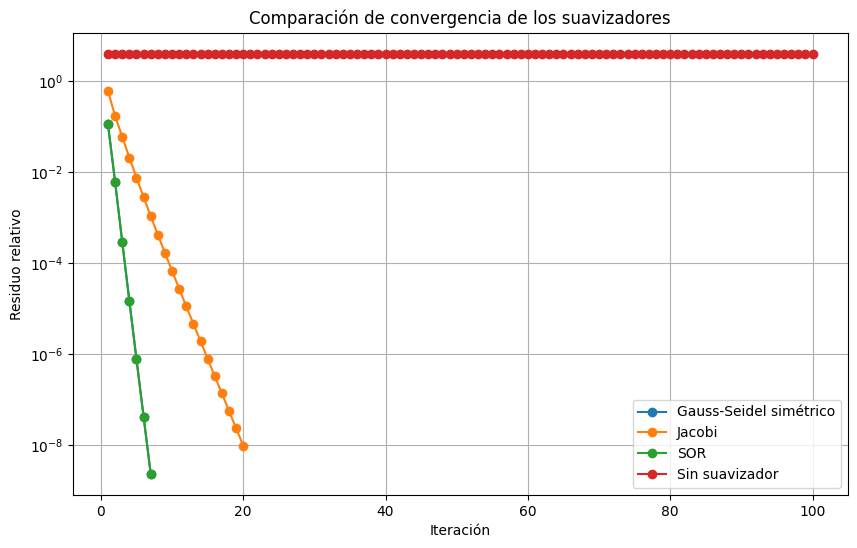

In [10]:
plt.figure(figsize=(10, 6))

for resultado in resultados:

    residuos = resultado["Residuos"]

    plt.semilogy(
        range(1, len(residuos) + 1),
        residuos,
        marker="o",
        label=resultado["Configuración"]
    )

plt.xlabel("Iteración")
plt.ylabel("Residuo relativo")
plt.title("Comparación de convergencia de los suavizadores")
plt.grid(True)
plt.legend()
plt.show()

Análisis de los resultados:

La gráfica permite identificar diferencias importantes en la velocidad de convergencia de los suavizadores:
- Gauss-Seidel simétrico y SOR: presentan una reducción rápida del residuo relativo y alcanzan la tolerancia establecida en aproximadamente 7 iteraciones.
- Jacobi: muestra una disminución progresiva del residuo y necesita aproximadamente 20 iteraciones para alcanzar la convergencia.
- Sin suavizador: mantiene el residuo relativo en valores elevados, sin mostrar una reducción significativa durante las 100 iteraciones permitidas.

En conclusión, la representación gráfica evidencia la importancia de los suavizadores en los métodos multigrid, ya que contribuyen a reducir el error y mejorar la convergencia del proceso iterativo. En este experimento, Gauss-Seidel simétrico y SOR presentan el mejor comportamiento, mientras que la ausencia de suavización impide obtener una solución convergente bajo las condiciones establecidas.

En esta celda se establecen diferentes combinaciones de suavizadores para analizar cómo influye su aplicación, tanto antes como después de la corrección, en el comportamiento del método multigrid Ruge-Stüben.

Inicialmente, se definen dos configuraciones individuales:
- GS (Gauss-Seidel): utiliza el método Gauss-Seidel con barrido simétrico.
- JAC (Jacobi): utiliza el método Jacobi con un parámetro de relajación \(\omega=0.7\).
Posteriormente, se construye el diccionario combinaciones, en el cual se establecen siete alternativas de suavización:
1. GS / GS: aplica Gauss-Seidel antes y después de la corrección.
2. Jacobi / Jacobi: utiliza Jacobi en ambas etapas.
3. Jacobi / GS: combina Jacobi como suavizador previo y Gauss-Seidel como posterior.
4. GS / Jacobi: invierte la combinación anterior.
5. Ninguno / GS: no aplica suavización previa, pero utiliza Gauss-Seidel posteriormente.
6. GS / Ninguno: aplica Gauss-Seidel previamente y omite la suavización posterior.
7. Ninguno / Ninguno: no utiliza suavizadores en ninguna de las dos etapas.

El propósito de esta configuración es estudiar si la elección y combinación de los suavizadores previos y posteriores afectan la velocidad de convergencia, el número de iteraciones y el costo computacional.

In [11]:
GS = (
    "gauss_seidel",
    {"sweep": "symmetric"}
)

JAC = (
    "jacobi",
    {"omega": 0.7}
)

combinaciones = {
    "GS / GS": (GS, GS),
    "Jacobi / Jacobi": (JAC, JAC),
    "Jacobi / GS": (JAC, GS),
    "GS / Jacobi": (GS, JAC),
    "Ninguno / GS": (None, GS),
    "GS / Ninguno": (GS, None),
    "Ninguno / Ninguno": (None, None)
}

En esta celda se evalúan las siete combinaciones de suavizadores previamente definidas, con el propósito de analizar la influencia que tiene la selección independiente del suavizador previo (presmoother) y posterior (postsmoother) en el desempeño del método multigrid Ruge-Stüben.

Para ello, se recorre el diccionario combinaciones mediante un ciclo for. En cada ejecución se extraen los suavizadores correspondientes y se construye un diccionario de configuración que posteriormente se envía a la función ejecutar_experimento().

Los resultados de cada experimento se almacenan en la lista resultados_combinaciones, conservando información sobre el número de iteraciones, el residuo relativo final y el tiempo de solución. Finalmente, se imprimen estos indicadores para facilitar la comparación entre las diferentes alternativas.

In [12]:
resultados_combinaciones = []

for nombre, (pre, post) in combinaciones.items():

    configuracion = {
        "presmoother": pre,
        "postsmoother": post
    }

    resultado = ejecutar_experimento(
        nombre,
        configuracion
    )

    resultados_combinaciones.append(resultado)

    print(
        nombre,
        "| Iteraciones:", resultado["Iteraciones"],
        "| Residuo:", resultado["Residuo relativo"],
        "| Tiempo:", resultado["Tiempo solución (s)"]
    )

GS / GS | Iteraciones: 7 | Residuo: 2.3998374535959877e-09 | Tiempo: 0.024712417000046116
Jacobi / Jacobi | Iteraciones: 21 | Residuo: 4.228882585847223e-09 | Tiempo: 0.01144035300012547
Jacobi / GS | Iteraciones: 8 | Residuo: 6.239397292497329e-09 | Tiempo: 0.004927170999962982
GS / Jacobi | Iteraciones: 10 | Residuo: 4.025603276612421e-09 | Tiempo: 0.006125901999894268
Ninguno / GS | Iteraciones: 10 | Residuo: 1.885707744274649e-09 | Tiempo: 0.0049092319998180756
GS / Ninguno | Iteraciones: 13 | Residuo: 6.3806673946599875e-09 | Tiempo: 0.006320151999943846
Ninguno / Ninguno | Iteraciones: 100 | Residuo: 3.927238562227951 | Tiempo: 0.02248814500012486


Análisis de los resultados:

Los resultados permiten identificar los siguientes comportamientos:
- GS / GS: alcanza la convergencia en 7 iteraciones, mostrando una reducción rápida del residuo.
- Jacobi / Jacobi: requiere 21 iteraciones, evidenciando una convergencia más lenta que Gauss-Seidel.
- Jacobi / GS: alcanza la convergencia en 8 iteraciones, mostrando que combinar ambos suavizadores mejora considerablemente el comportamiento respecto a utilizar únicamente Jacobi.
- GS / Jacobi: necesita 10 iteraciones para alcanzar la tolerancia establecida.
- Ninguno / GS: converge en 10 iteraciones y obtiene el menor residuo relativo de todas las configuraciones.
- GS / Ninguno: alcanza la convergencia en 13 iteraciones, mostrando que omitir la suavización posterior afecta el desempeño del método.
- Ninguno / Ninguno: no alcanza la convergencia dentro del límite de 100 iteraciones.

En conclusión, los resultados muestran que la combinación de suavizadores previos y posteriores influye directamente en la convergencia del método multigrid. En particular, Gauss-Seidel simétrico en ambas etapas presenta el menor número de iteraciones, mientras que la combinación sin suavizadores no consigue resolver satisfactoriamente el sistema.

En esta celda se construye un DataFrame mediante la biblioteca pandas, con el propósito de organizar y visualizar los resultados obtenidos al evaluar las siete combinaciones de suavizadores previos y posteriores del método multigrid Ruge-Stüben.

A partir de la lista resultados_combinaciones, se extraen cuatro indicadores para cada experimento:
- Combinación: identifica los suavizadores utilizados en las etapas previa y posterior.
- Iteraciones: representa el número de iteraciones necesarias para alcanzar la convergencia.
- Tiempo de solución (s): indica el tiempo computacional empleado para resolver el sistema lineal.
- Residuo relativo: mide el error relativo final de la solución obtenida.

La función pd.DataFrame() permite organizar esta información en una estructura tabular, mientras que display() presenta los resultados de manera ordenada.

In [13]:
tabla_combinaciones = pd.DataFrame([
    {
        "Combinación": r["Configuración"],
        "Iteraciones": r["Iteraciones"],
        "Tiempo solución (s)": r["Tiempo solución (s)"],
        "Residuo relativo": r["Residuo relativo"]
    }
    for r in resultados_combinaciones
])

display(tabla_combinaciones)

,Combinación,Iteraciones,Tiempo solución (s),Residuo relativo
0,GS / GS,7,0.024712,2.399837e-09
1,Jacobi / Jacobi,21,0.011440,4.228883e-09
2,Jacobi / GS,8,0.004927,6.239397e-09
3,GS / Jacobi,10,0.006126,4.025603e-09
4,Ninguno / GS,10,0.004909,1.885708e-09
5,GS / Ninguno,13,0.006320,6.380667e-09
6,Ninguno / Ninguno,100,0.022488,3.927239e+00


Análisis de los resultados:

La tabla permite observar que la combinación GS / GS presenta el menor número de iteraciones, alcanzando la convergencia en 7 iteraciones. Sin embargo, las combinaciones Jacobi / GS y Ninguno / GS presentan los menores tiempos de solución, con aproximadamente $0.00493$s y $0.00491$s, respectivamente.

Por otra parte, la configuración Ninguno / GS obtiene el menor residuo relativo, mientras que Ninguno / Ninguno no logra converger dentro del límite de iteraciones establecido.

Esta comparación permite concluir que no necesariamente la combinación que requiere menos iteraciones es la más eficiente en términos de tiempo computacional. Por ello, resulta importante considerar conjuntamente el número de iteraciones, el tiempo de solución y el residuo relativo para determinar el comportamiento de cada configuración.

En esta celda se genera una gráfica para analizar cómo influye la combinación de suavizadores previos (pre-smoother) y posteriores (post-smoother) en la convergencia del método multigrid Ruge-Stüben.

Para construir la gráfica, se utiliza la biblioteca Matplotlib y se recorren los resultados almacenados en resultados_combinaciones. En cada iteración se extrae la lista de residuos relativos correspondiente a cada combinación y se representa mediante la función plt.semilogy(), que permite visualizar su evolución utilizando una escala logarítmica en el eje vertical.

La gráfica presenta las siguientes características:
- Eje horizontal: representa el número de iteraciones realizadas.
- Eje vertical: representa el residuo relativo en escala logarítmica.
- Curvas: identifican las siete combinaciones de suavizadores evaluadas.
- Marcadores: muestran la evolución del residuo relativo en cada iteración.

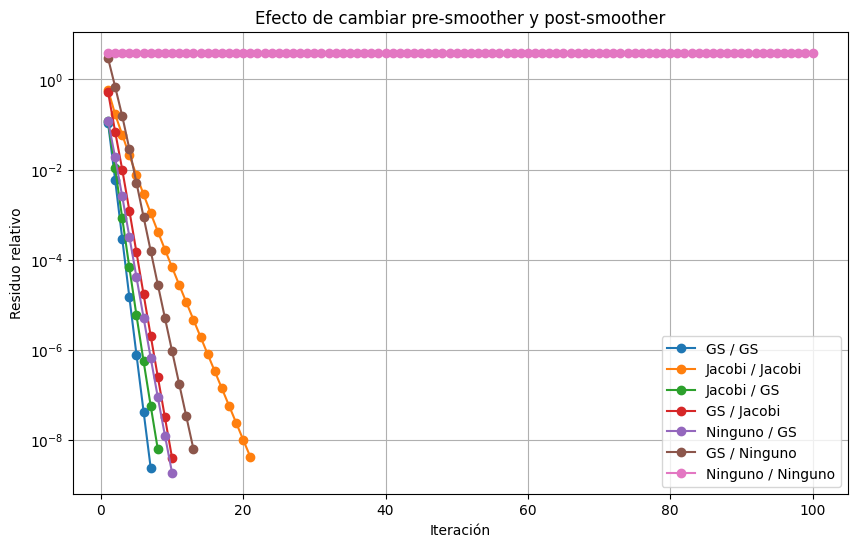

In [14]:
plt.figure(figsize=(10, 6))

for resultado in resultados_combinaciones:

    residuos = resultado["Residuos"]

    plt.semilogy(
        range(1, len(residuos) + 1),
        residuos,
        marker="o",
        label=resultado["Configuración"]
    )

plt.xlabel("Iteración")
plt.ylabel("Residuo relativo")
plt.title("Efecto de cambiar pre-smoother y post-smoother")
plt.grid(True)
plt.legend()
plt.show()

Análisis de los resultados:

La representación gráfica permite observar que:
- GS / GS: presenta una convergencia rápida, alcanzando la tolerancia establecida en 7 iteraciones.
- Jacobi / Jacobi: muestra una reducción más lenta del residuo, necesitando 21 iteraciones.
- Jacobi / GS: mejora considerablemente la convergencia respecto a utilizar Jacobi en ambas etapas, alcanzando la tolerancia en 8 iteraciones.
- GS / Jacobi: presenta una convergencia intermedia, con 10 iteraciones.
- Ninguno / GS: consigue una reducción efectiva del residuo en 10 iteraciones, incluso sin aplicar suavización previa.
- GS / Ninguno: alcanza la convergencia en 13 iteraciones, mostrando que la ausencia de suavización posterior afecta el proceso.
- Ninguno / Ninguno: mantiene el residuo relativo en valores elevados y no consigue converger durante las 100 iteraciones.
En conclusión, la gráfica permite evidenciar que tanto la elección como el orden de aplicación de los suavizadores influyen en la velocidad de convergencia. En particular, se observa que utilizar Gauss-Seidel como suavizador posterior favorece el proceso de reducción del residuo en las combinaciones evaluadas.